In [1]:
pip install osmnx mapclassify folium overturemaps

Note: you may need to restart the kernel to use updated packages.


In [2]:
import os
import math
import getpass
import requests
import pandas as pd
import geopandas as gpd
import networkx as nx
import osmnx as ox
import matplotlib.pyplot as plt
from shapely.ops import unary_union

print("Ready! OSMnx version", ox.__version__)
print("Files in data/:", sorted(os.listdir("lab5_data/data")))

Ready! OSMnx version 1.5.0
Files in data/: ['.ipynb_checkpoints', 'EDI_DataZones', 'EconomicEDI.csv', 'city_buildings.gpkg', 'city_parks.gpkg', 'city_walk.graphml', 'dundee_overture_places.gpkg', 'dundee_services.gpkg', 'dundee_walk.graphml', 'edinburgh_growth.csv', 'edinburgh_north_services.gpkg', 'ohsome_edinburgh_north_count_timeline_2026-01-01.json', 'ohsome_edinburgh_north_length_timeline_2026-01-01.json', 'ohsome_edinburgh_north_streets_by_datazone_2012-01-01_2026-01-01.json', 'ohsome_metadata.json', 'perth_bike.graphml', 'perth_residential.gpkg', 'perth_services.gpkg', 'perth_walk.graphml']


# Lab 5
## Challenge 1
— Change `BBOX` to another place (find coordinates at https://bboxfinder.com, choose the format *west, south, east, north*). Does the pattern repeat?

My API key: eyJvcmciOiI1YjNjZTM1OTc4NTExMTAwMDFjZjYyNDgiLCJpZCI6ImUxYTIwZWVjMzU0MjQ1MDZhOGRiNjYwNTU1NmRjODkwIiwiaCI6Im11cm11cjY0In0=

For this challenge, I changed the coordinates to create a box around Port of Spain, Trinidad using the coordinates `BBOX = [-61.538715,10.648714,-61.502666,10.676550]`. The pattern interestingly does not seem to repeat, and showed a decline in residential streets in the city. This could indicate a change in updates to the OSM, where more focus was placed on mapping buildings than residential streets.

In [3]:
API_KEY = getpass.getpass("Paste your ohsome API key: ")

Paste your ohsome API key:  ········


In [4]:
OHSOME_URL = "https://api.heigit.org/ohsome-api/v2-rc/stats/features/"
# changing the coordinates to create a box around Port of Spain, Trinidad
BBOX = [-61.538715,10.648714,-61.502666,10.676550]          # Port of Spain, Trinidad

def ohsome(measure, osm_filter):
    body = {"aoi": BBOX,
            "filter": osm_filter,
            "time": {"start": "2008-01-01", "end": "2026-01-01", "interval": "P1Y"}}
    response = requests.post(OHSOME_URL + measure + ".json", json=body,
                             headers={"Authorization": API_KEY}, timeout=300)
    response.raise_for_status()               # stops here with a message if something went wrong
    result = response.json()["result"]
    years = [int(t[:4]) for t in result["timestamp"]]
    return pd.Series(result["value"], index=years)

buildings = ohsome("count", "building=* and geometry:polygon")
streets = ohsome("length", "highway in (residential, living_street) and type:way") / 1000   # metres -> km

growth = pd.DataFrame({"Buildings (count)": buildings, "Residential streets (km)": streets})
growth

,Buildings (count),Residential streets (km)
2008,0,0.000
2009,0,0.000
2010,0,49.965
2011,0,50.065
2012,280,103.587
2013,967,103.103
2014,991,102.030
2015,999,101.230
2016,1294,96.474
2017,1593,84.032


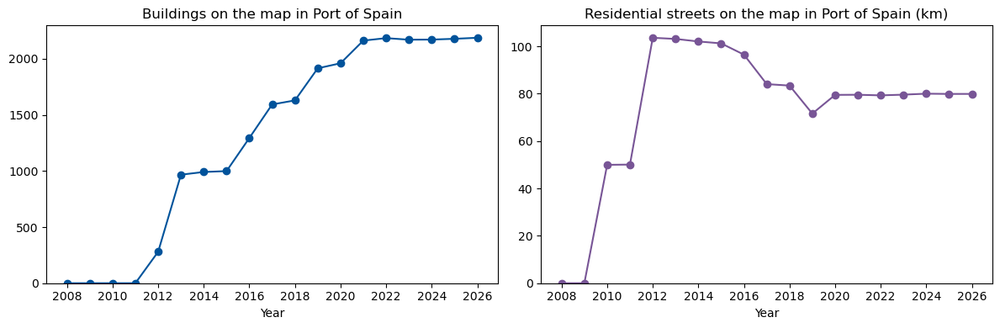

Change from 2012 to 2026 (%):
Buildings (count)           681.0
Residential streets (km)    -23.0
dtype: float64


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
growth["Buildings (count)"].plot(ax=axes[0], marker="o", color="#00539B", title="Buildings on the map in Port of Spain")
growth["Residential streets (km)"].plot(ax=axes[1], marker="o", color="#785596", title="Residential streets on the map in Port of Spain (km)")
for ax in axes:
    ax.set_ylim(bottom=0)
    ax.set_xlabel("Year")
    ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))   # whole years on the axis
plt.tight_layout()
plt.show()

change = (growth.loc[2026] / growth.loc[2012] - 1) * 100
print("Change from 2012 to 2026 (%):")
print(change.round(0))

## Challenge 2

### Challenge 2.1

Measure access to something else. In 2.1, change `"Food shop"` to `"Pharmacy"`, `"GP"` or `"School"` and run Part 2 again.

I measured access to pharmacies, and found that most of them are accessible from the city centre and are less conveniently-placed for someone coming from the norther outskirts of the city centre.

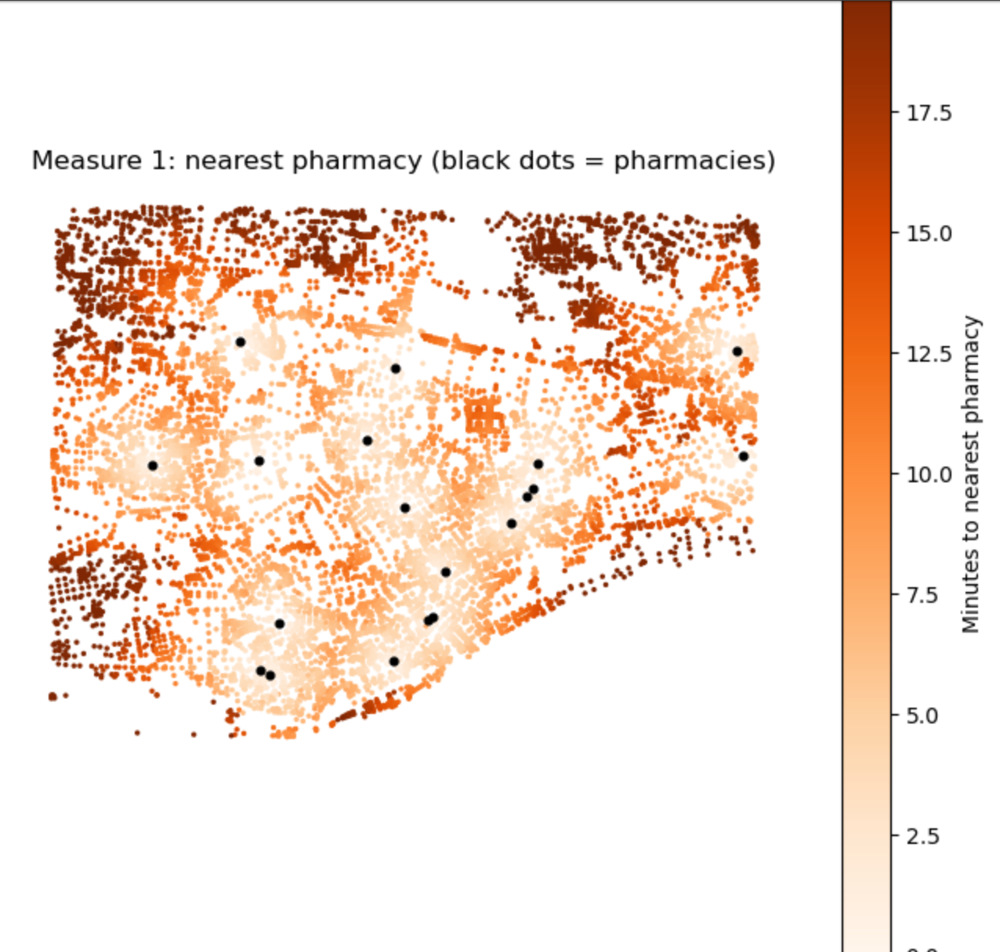

In [6]:
WALK_SPEED = 80                    # metres per minute (4.8 km/h)

G = ox.load_graphml("lab5_data/data/dundee_walk.graphml")
G = ox.project_graph(G, to_crs="EPSG:27700")            # British National Grid: distances in metres
nodes, edges = ox.graph_to_gdfs(G)

dundee_services = gpd.read_file("lab5_data/data/dundee_services.gpkg").to_crs("EPSG:27700")
print(dundee_services["service"].value_counts())

# selecting Pharmacy as the new service to analyse
pharmacies = dundee_services[dundee_services["service"] == "Pharmacy"].copy()
print(len(nodes), "street junctions and", len(pharmacies), "pharmacies")

service
Food shop    104
School        28
Pharmacy      19
GP            11
Name: count, dtype: int64
12777 street junctions and 19 pharmacies


In [7]:
# assigning each named pharmacy a node
pharmacies["node"] = ox.distance.nearest_nodes(G, pharmacies.geometry.x, pharmacies.geometry.y)
pharmacies[["name", "node"]].head()

,name,node
104,Houston Pharmacy,299735961
105,Boots,7822035576
106,FergusMacfarlane,12093126276
107,Wallacetown Pharmacy,11649699300
108,Richardson Pharmacy,7229617638


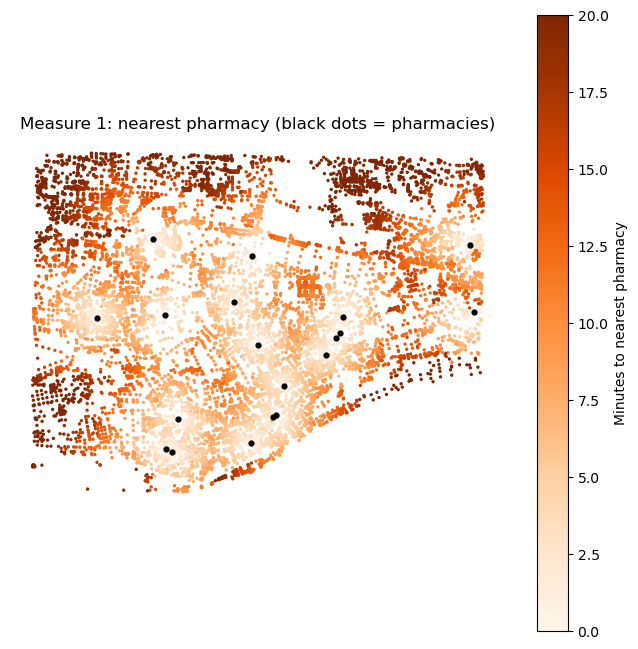

In [8]:
# creating the plot, with lighter values indicating shorter walk time to the pharmacy
nearest = nx.multi_source_dijkstra_path_length(G, set(pharmacies["node"]), weight="length")
nodes["nearest_min"] = pd.Series(nearest) / WALK_SPEED

ax = nodes.plot(column="nearest_min", cmap="Oranges", vmax=20, markersize=2, legend=True, figsize=(8, 8),
                legend_kwds={"label": "Minutes to nearest pharmacy"})
pharmacies.plot(ax=ax, color="black", markersize=12)
ax.set_title("Measure 1: nearest pharmacy (black dots = pharmacies)")
ax.set_axis_off()
plt.show()

### Challenge 2.2

Try `BETA = 0.14` (half weight at 5 minutes). Who might this steeper decay represent?

This decay would represent people with mobility impairments, elderly people, children, or people carrying things.

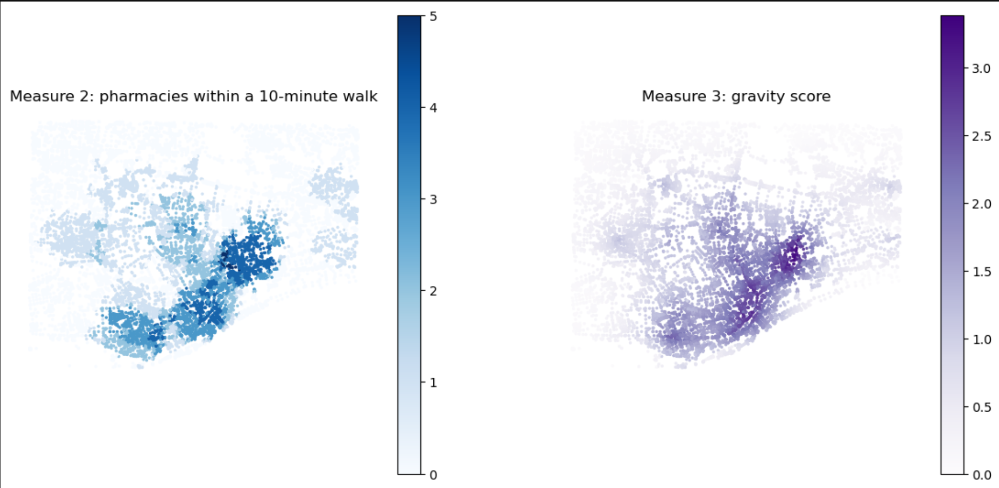

In [9]:
# Challenge 2.2: BETA = 0.14 (half weight at 5 minutes)
BETA = 0.14 #beta parameter for gravity model, based on 5-minute half-life (ln(2)/5)

cumulative = {node: 0 for node in G.nodes}      # start every junction at zero
gravity = {node: 0.0 for node in G.nodes}

for pharmacies_node in pharmacies["node"]:
    distances = nx.single_source_dijkstra_path_length(G, pharmacies_node, cutoff=30 * WALK_SPEED, weight="length")
    for node, metres in distances.items():
        minutes = metres / WALK_SPEED
        if minutes <= 10:
            cumulative[node] += 1
        gravity[node] += math.exp(-BETA * minutes)

nodes["cumulative"] = pd.Series(cumulative)
nodes["gravity"] = pd.Series(gravity)

nodes[["nearest_min", "cumulative", "gravity"]].describe().round(2)

,nearest_min,cumulative,gravity
count,12777.00,12777.00,12777.00
mean,10.05,1.22,1.01
std,6.58,1.35,0.79
min,0.00,0.00,0.00
25%,4.83,0.00,0.29
50%,8.30,1.00,0.84
75%,14.08,2.00,1.67
max,39.50,5.00,3.38


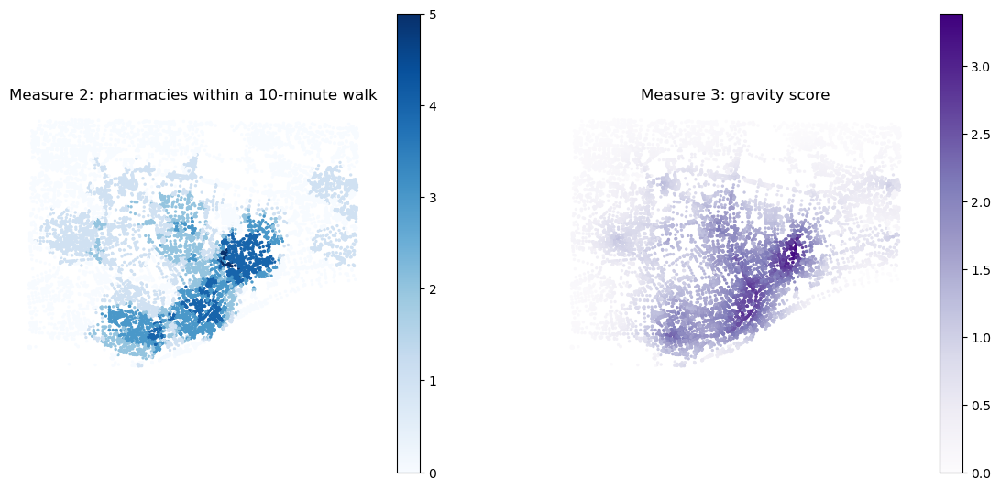

In [10]:
# closest pharmacies and gravity plot, with BETA = 0.14 (half weight at 5 minutes)
fig, axes = plt.subplots(1, 2, figsize=(14, 6.5))
nodes.plot(ax=axes[0], column="cumulative", cmap="Blues", markersize=2, legend=True)
axes[0].set_title("Measure 2: pharmacies within a 10-minute walk")
nodes.plot(ax=axes[1], column="gravity", cmap="Purples", markersize=2, legend=True)
axes[1].set_title("Measure 3: gravity score")
for ax in axes:
    ax.set_axis_off()
plt.show()

## Challenge 3

### Challenge 3.1 
Change the confidence threshold (CT) in 3.3 from `0.5` to `0.8`. How many Overture shops are left, and how does the comparison table change?

When CT = 0.5, there are 121 Overture shops, when CT = 0.8, there are 90 shops. In the comparison tables, the median minutes to the nearest food shop increases from 4.1 when CT = 0.5 to 4.7 when CT = 0.8. The % of junctions within 10 minutes decreases from 87.7 to 81.9. The OSM data walk times of 3.9 mins and % of junctions within 10 minutes of 87.5%. The OSM values became higher than the Overture data when the Overture CT was 0.8.

In [11]:
import overturemaps

In [12]:
DUNDEE_BOX = (-3.024, 56.438, -2.926, 56.492)        # west, south, east, north

table = overturemaps.record_batch_reader("place", bbox=DUNDEE_BOX, stac=True).read_all()
places = table.to_pandas()
places["geometry"] = gpd.GeoSeries.from_wkb(places["geometry"])
places = gpd.GeoDataFrame(places, geometry="geometry", crs="EPSG:4326").to_crs("EPSG:27700")
places["name"] = places["names"].str.get("primary")      # each place can have several names; keep the main one

print(len(places), "Overture places in Dundee")

6657 Overture places in Dundee


In [13]:
WALK_SPEED = 80                    # metres per minute (4.8 km/h)

G = ox.load_graphml("lab5_data/data/dundee_walk.graphml")
G = ox.project_graph(G, to_crs="EPSG:27700")            # British National Grid: distances in metres
nodes, edges = ox.graph_to_gdfs(G)

dundee_services = gpd.read_file("lab5_data/data/dundee_services.gpkg").to_crs("EPSG:27700")
print(dundee_services["service"].value_counts())

shops = dundee_services[dundee_services["service"] == "Food shop"].copy()
print(len(nodes), "street junctions and", len(shops), "food shops")

service
Food shop    104
School        28
Pharmacy      19
GP            11
Name: count, dtype: int64
12777 street junctions and 104 food shops


In [14]:
# assigning nodes to the shops in Dundee
shops["node"] = ox.distance.nearest_nodes(G, shops.geometry.x, shops.geometry.y)
shops[["name", "node"]].head()

# defining how to find the nearest food nodes
nearest_food = nx.multi_source_dijkstra_path_length(G, set(shops["node"]), weight="length")
nodes["nearest_min"] = pd.Series(nearest_food) / WALK_SPEED

In [15]:
# initial confidence threshold of 0.5
is_food = places["basic_category"].str.contains("grocery|supermarket|convenience", na=False)
overture_shops = places[is_food & (places["confidence"] >= 0.5)].copy()

print(overture_shops["basic_category"].value_counts())
print()
print("Food shops in OpenStreetMap:", len(shops))
print("Food shops in Overture:     ", len(overture_shops))

basic_category
convenience_store    121
Name: count, dtype: int64

Food shops in OpenStreetMap: 104
Food shops in Overture:      121


In [16]:
# commparison table when CT = 0.5
overture_shops["node"] = ox.distance.nearest_nodes(G, overture_shops.geometry.x, overture_shops.geometry.y)
nearest_overture = nx.multi_source_dijkstra_path_length(G, set(overture_shops["node"]), weight="length")
nodes["nearest_min_overture"] = pd.Series(nearest_overture) / WALK_SPEED

comparison = pd.DataFrame({
    "OpenStreetMap": [nodes["nearest_min"].median(), (nodes["nearest_min"] <= 10).mean() * 100],
    "Overture":      [nodes["nearest_min_overture"].median(), (nodes["nearest_min_overture"] <= 10).mean() * 100],
}, index=["Median minutes to nearest food shop", "% of junctions within 10 minutes"])
comparison.round(1)

,OpenStreetMap,Overture
Median minutes to nearest food shop,3.9,4.1
% of junctions within 10 minutes,87.5,87.7


In [17]:
# new confidence threshold of 0.8
is_food = places["basic_category"].str.contains("grocery|supermarket|convenience", na=False)
overture_shops_higherconf = places[is_food & (places["confidence"] >= 0.8)].copy()

print(overture_shops_higherconf["basic_category"].value_counts())
print()
print("Food shops in OpenStreetMap:", len(shops))
print("Food shops in Overture:     ", len(overture_shops_higherconf))

basic_category
convenience_store    90
Name: count, dtype: int64

Food shops in OpenStreetMap: 104
Food shops in Overture:      90


In [18]:
# comparison table with the higher CT value of 0.8
overture_shops_higherconf["node"] = ox.distance.nearest_nodes(G, overture_shops_higherconf.geometry.x, overture_shops_higherconf.geometry.y)
nearest_overture_higherconf = nx.multi_source_dijkstra_path_length(G, set(overture_shops_higherconf["node"]), weight="length")
nodes["nearest_min_overture"] = pd.Series(nearest_overture_higherconf) / WALK_SPEED

comparison_higherconf = pd.DataFrame({
    "OpenStreetMap": [nodes["nearest_min"].median(), (nodes["nearest_min"] <= 10).mean() * 100],
    "Overture":      [nodes["nearest_min_overture"].median(), (nodes["nearest_min_overture"] <= 10).mean() * 100],
}, index=["Median minutes to nearest food shop", "% of junctions within 10 minutes"])
comparison_higherconf.round(1)

,OpenStreetMap,Overture
Median minutes to nearest food shop,3.9,4.7
% of junctions within 10 minutes,87.5,81.9


### Challenge 3.2
Look at the category list in 3.2 again and pick another service, for example `pharmacy`. Change the words in `str.contains(...)` and compare with the OSM pharmacies (`dundee_services`) from Part 2.

Compared to the OSM pharmacies from Challenge 2.1, the Overture data for pharmacies are more spread out and less evenly distributed (e.g. there are some points clustered together but further away from other pharmacies). The Overture points are more numerous (34) than the OSM points (19) but are less evenly distributed across Dundee.

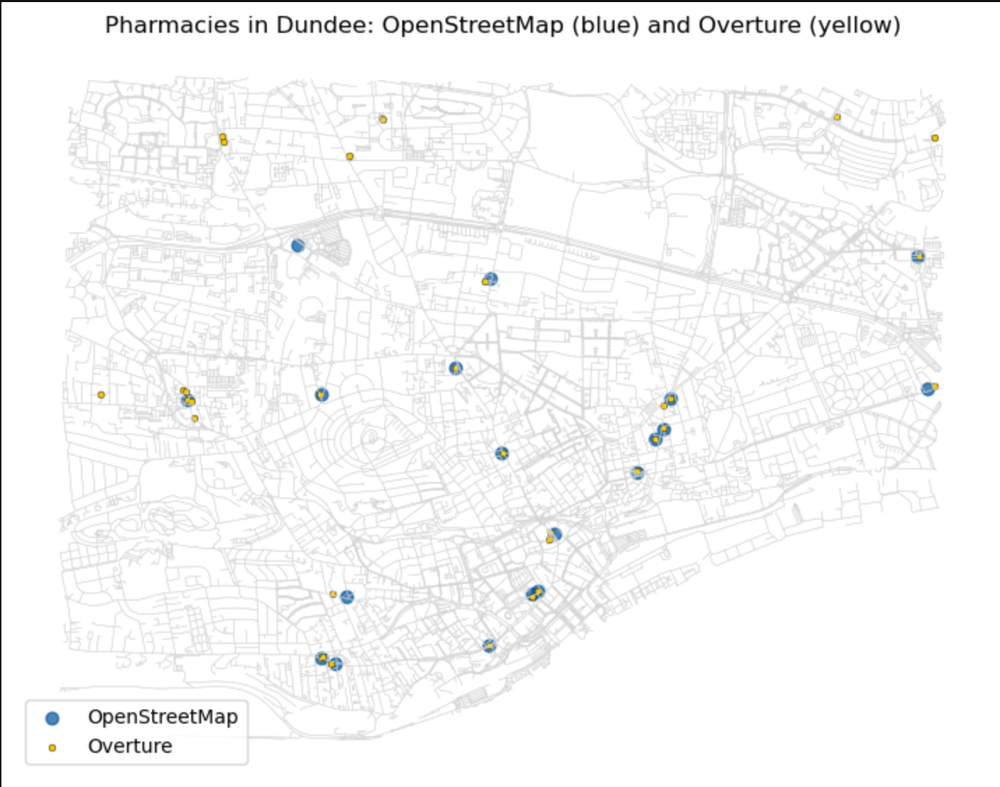 

In [19]:
# getting data from overture on Dundee pharmacies
WALK_SPEED = 80                    # metres per minute (4.8 km/h)

G = ox.load_graphml("lab5_data/data/dundee_walk.graphml")
G = ox.project_graph(G, to_crs="EPSG:27700")            # British National Grid: distances in metres
nodes, edges = ox.graph_to_gdfs(G)

dundee_services = gpd.read_file("lab5_data/data/dundee_services.gpkg").to_crs("EPSG:27700")
print(dundee_services["service"].value_counts())

pharmacies = dundee_services[dundee_services["service"] == "Pharmacy"].copy()
print(len(nodes), "street junctions and", len(pharmacies), "pharmacies")

service
Food shop    104
School        28
Pharmacy      19
GP            11
Name: count, dtype: int64
12777 street junctions and 19 pharmacies


In [20]:
# selecting places that are pharmacies with >= 50% confidence threshold
is_pharm = places["basic_category"].str.contains("pharmacy", na=False)
overture_pharm = places[is_pharm & (places["confidence"] >= 0.5)].copy()

print(overture_pharm["basic_category"].value_counts())
print()
print("Pharmacies in OpenStreetMap:", len(pharmacies))
print("Pharmacies in Overture:     ", len(overture_pharm))

basic_category
pharmacy_and_drug_store    34
Name: count, dtype: int64

Pharmacies in OpenStreetMap: 19
Pharmacies in Overture:      34


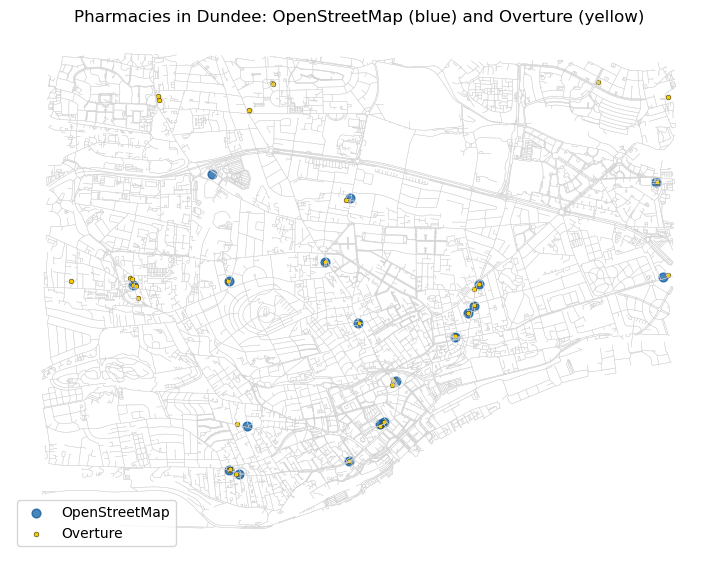

In [21]:
# creating plot of both OSM and overture pharmacies
fig, ax = plt.subplots(figsize=(9, 9))
edges.plot(ax=ax, color="lightgrey", linewidth=0.3)
pharmacies.plot(ax=ax, color="#00539B", markersize=40, label="OpenStreetMap", alpha=0.7)
overture_pharm.plot(ax=ax, color="#F4C900", markersize=12, label="Overture", edgecolor="black", linewidth=0.3)
ax.legend(loc="lower left")
ax.set_title("Pharmacies in Dundee: OpenStreetMap (blue) and Overture (yellow)")
ax.set_axis_off()
plt.show()

## Challenge 4

Scotland's local living goal is about 10 minutes each way. Change `WALK_LIMIT` to `800` and run 4.4 and 4.5 again. How many homes still reach all five services?

30% of all homes reach all 5 services within a 10 minute walk (when ```WALK_LIMIT = 800```).

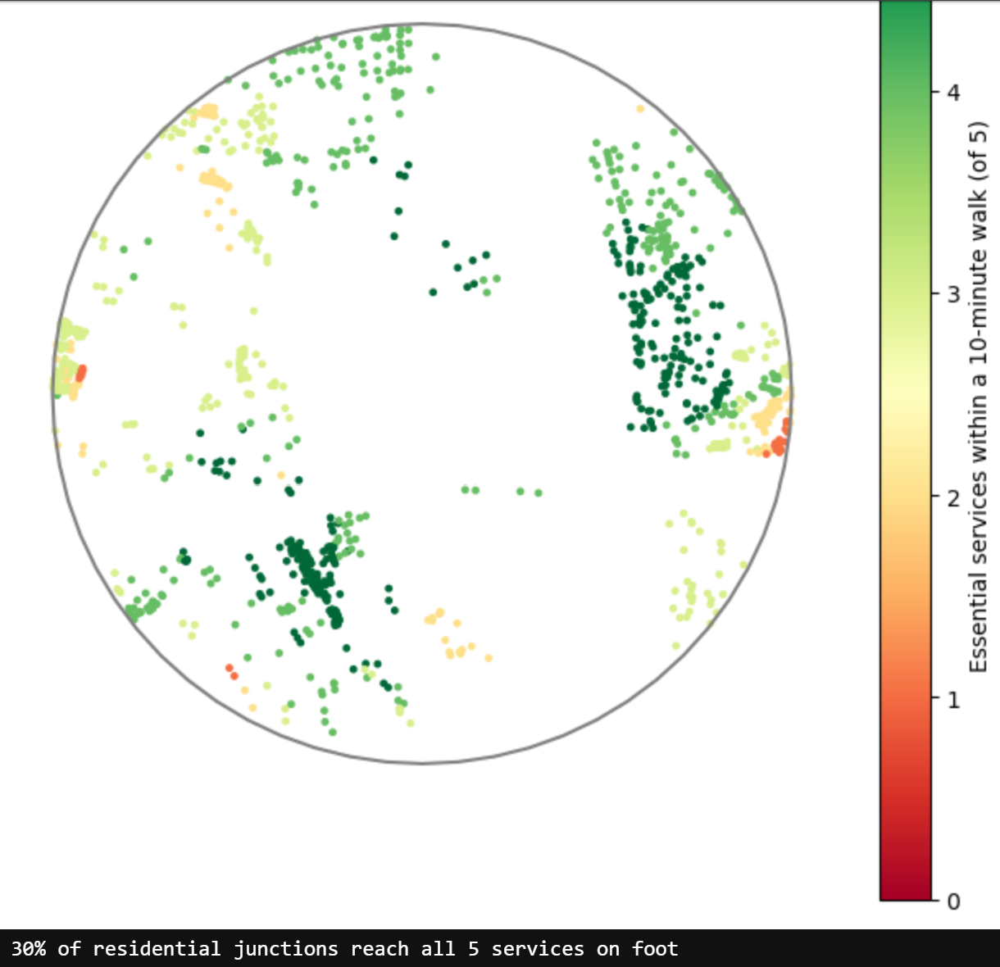

In [22]:
PERTH = (56.3960, -3.4370)       
PERTH_AREA = 1500     # metres: the neighbourhood area we study, also to reflect the 15-minute neighbourhood concept (15 minutes walking = 1200 metres, 20 minutes cycling = 5000 metres)
PERTH_WALK_LIMIT = 800   # changed to 800 to represent 10 minutes walking
PERTH_BIKE_LIMIT = 5000  # 20 minutes cycling

# dictionary of Perth services
SERVICES = {
    "School":           {"amenity": "school"},
    "Food shop":        {"shop": ["supermarket", "convenience", "greengrocer"]},
    "Healthcare":       {"amenity": ["doctors", "clinic", "pharmacy", "hospital"]},
    "Park":             {"leisure": "park"},
    "Public transport": {"highway": "bus_stop", "railway": "station"},
}

In [23]:
G_walkperth = ox.load_graphml("lab5_data/data/perth_walk.graphml")
G_walkperth = ox.project_graph(G_walkperth, to_crs="EPSG:27700").to_undirected()

G_bikeperth = ox.load_graphml("lab5_data/data/perth_bike.graphml")
G_bikeperth = ox.project_graph(G_bikeperth, to_crs="EPSG:27700").to_undirected()

print("Walk network:", len(G_walkperth), "junctions | Bike network:", len(G_bikeperth), "junctions")

Walk network: 6595 junctions | Bike network: 9236 junctions


In [24]:
walk_nodes, walk_edges = ox.graph_to_gdfs(G_walkperth)

# rading residential data to know where homes are
residential = gpd.read_file("lab5_data/data/perth_residential.gpkg").to_crs("EPSG:27700")
residential_area = unary_union(list(residential.geometry))

centre = gpd.GeoSeries.from_xy([PERTH[1]], [PERTH[0]], crs="EPSG:4326").to_crs("EPSG:27700")
neighbourhood = centre.buffer(PERTH_AREA).iloc[0]

homes_perth = walk_nodes[walk_nodes.within(residential_area) & walk_nodes.within(neighbourhood)].copy()
print(len(homes_perth), "residential junctions in the neighbourhood")

1067 residential junctions in the neighbourhood


In [25]:
services_perth = gpd.read_file("lab5_data/data/perth_services.gpkg").to_crs("EPSG:27700")
homes_on_bike = ox.distance.nearest_nodes(G_bikeperth, homes_perth.geometry.x, homes_perth.geometry.y)   # the same homes on the bike network

# assigning points to each instance of a service using the dictionary and .gpkg file
for name in SERVICES:
    points = services_perth[services_perth["service"] == name].geometry

    walk_targets = ox.distance.nearest_nodes(G_walkperth, points.x, points.y)
    bike_targets = ox.distance.nearest_nodes(G_bikeperth, points.x, points.y)
    walk_dist = nx.multi_source_dijkstra_path_length(G_walkperth, set(walk_targets), weight="length")
    bike_dist = nx.multi_source_dijkstra_path_length(G_bikeperth, set(bike_targets), weight="length")

    homes_perth[name + " walk (m)"] = [walk_dist.get(n) for n in homes_perth.index]
    homes_perth[name + " bike (m)"] = [bike_dist.get(n) for n in homes_on_bike]
    print(f"{name:<17} {len(points):>5} found")

School               31 found
Food shop            48 found
Healthcare           29 found
Park                 28 found
Public transport    464 found


In [26]:
results = pd.DataFrame(index=list(SERVICES))
results["% homes within 10-min walk"] = [(homes_perth[s + " walk (m)"] <= PERTH_WALK_LIMIT).mean() * 100 for s in SERVICES]
results["% homes within 20-min cycle"] = [(homes_perth[s + " bike (m)"] <= PERTH_BIKE_LIMIT).mean() * 100 for s in SERVICES]
results.round(0)

,% homes within 10-min walk,% homes within 20-min cycle
School,65.0,100.0
Food shop,77.0,100.0
Healthcare,68.0,100.0
Park,65.0,100.0
Public transport,100.0,100.0


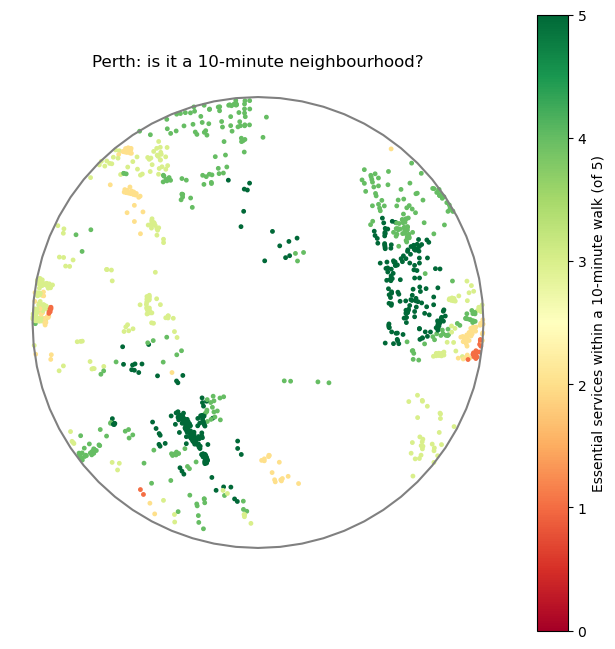

30% of residential junctions reach all 5 services on foot


In [27]:
# creating plot
homes_perth["services_walk"] = sum((homes_perth[s + " walk (m)"] <= PERTH_WALK_LIMIT).astype(int) for s in SERVICES)

ax = homes_perth.plot(column="services_walk", cmap="RdYlGn", vmin=0, vmax=5, markersize=6, legend=True,
                figsize=(8, 8), legend_kwds={"label": "Essential services within a 10-minute walk (of 5)"})
gpd.GeoSeries([neighbourhood], crs="EPSG:27700").boundary.plot(ax=ax, color="grey")
ax.set_title("Perth: is it a 10-minute neighbourhood?")
ax.set_axis_off()
plt.show()

print(f"{(homes_perth['services_walk'] == 5).mean():.0%} of residential junctions reach all 5 services on foot")

## Challenge 5

Change the services in 6.4 from `"Healthcare"` to `"Food shop"` or `"School"`. Where are the biggest gaps?

The biggest gaps in food shops are on the east side of the Tay River, and especially to the south-east of Perth, and to the south-west.

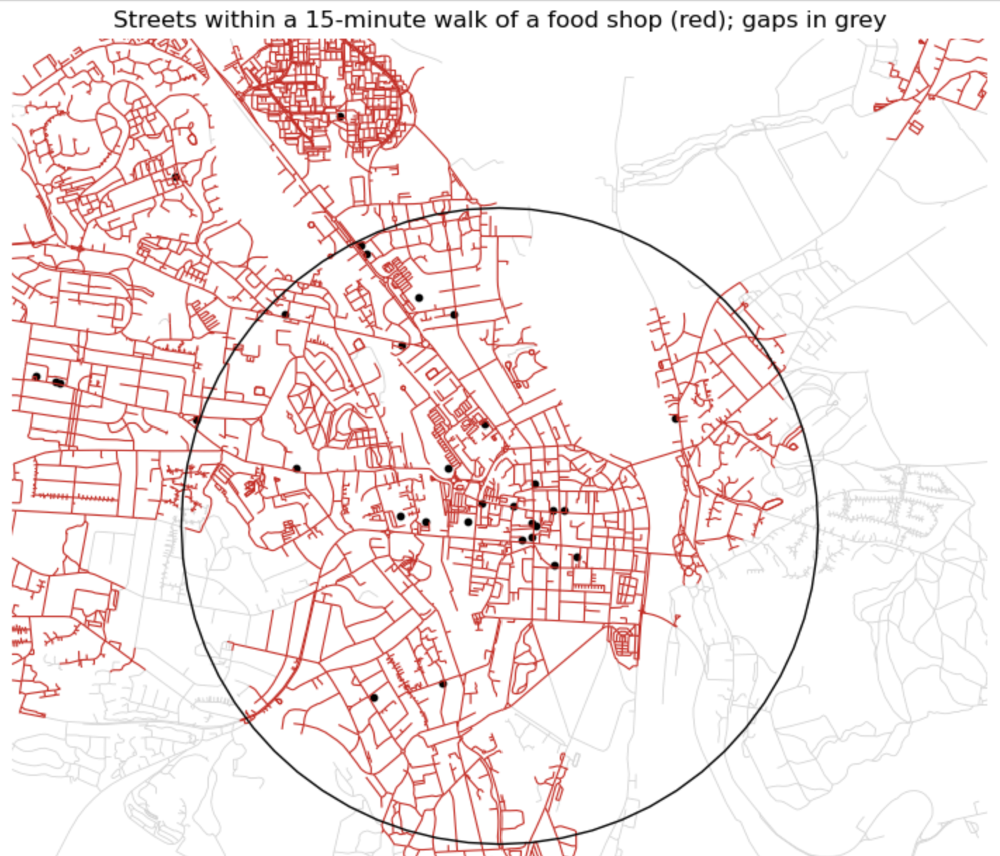

In [28]:
def isochrone(G_perth, start_node, metres):
    reachable = nx.ego_graph(G_perth, start_node, radius=metres, distance="length")
    streets = ox.graph_to_gdfs(reachable, nodes=False)
    return unary_union(list(streets.buffer(50)))

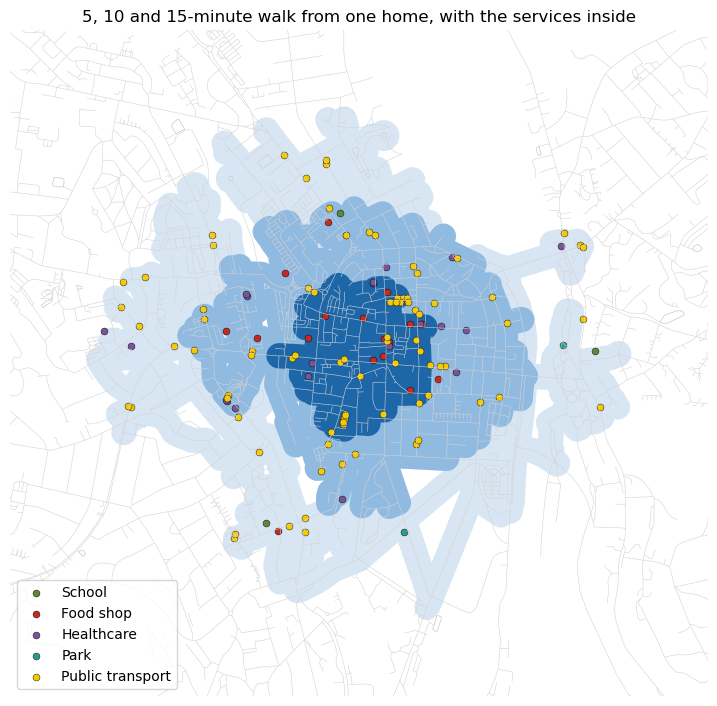

service
Public transport    88
Healthcare          21
Food shop           17
School               3
Park                 2
Name: count, dtype: int64


In [29]:
services_perth = gpd.read_file("lab5_data/data/perth_services.gpkg").to_crs("EPSG:27700")
home_perth = ox.distance.nearest_nodes(G_walkperth, centre.x.iloc[0], centre.y.iloc[0])   # the junction nearest the centre

fig, ax = plt.subplots(figsize=(9, 9))
walk_edges.plot(ax=ax, color="lightgrey", linewidth=0.4)
for minutes, colour in [(15, "#cfe0f0"), (10, "#7fb0dd"), (5, "#00539B")]:
    shape = isochrone(G_walkperth, home_perth, minutes * WALK_SPEED)
    gpd.GeoSeries([shape], crs="EPSG:27700").plot(ax=ax, color=colour, alpha=0.8)

iso15_perth = isochrone(G_walkperth, home_perth, 15 * WALK_SPEED)
inside_perth = services_perth[services_perth.within(iso15_perth)]
for name, colour in zip(SERVICES, ["#608738", "#C22A22", "#785596", "#2a9d8f", "#F4C900"]):
    inside_perth[inside_perth["service"] == name].plot(ax=ax, color=colour, markersize=25, label=name, edgecolor="black", linewidth=0.3)

ax.legend(loc="lower left")
ax.set_xlim(iso15_perth.bounds[0] - 300, iso15_perth.bounds[2] + 300)
ax.set_ylim(iso15_perth.bounds[1] - 300, iso15_perth.bounds[3] + 300)
ax.set_title("5, 10 and 15-minute walk from one home, with the services inside")
ax.set_axis_off()
plt.show()

print(inside_perth["service"].value_counts())

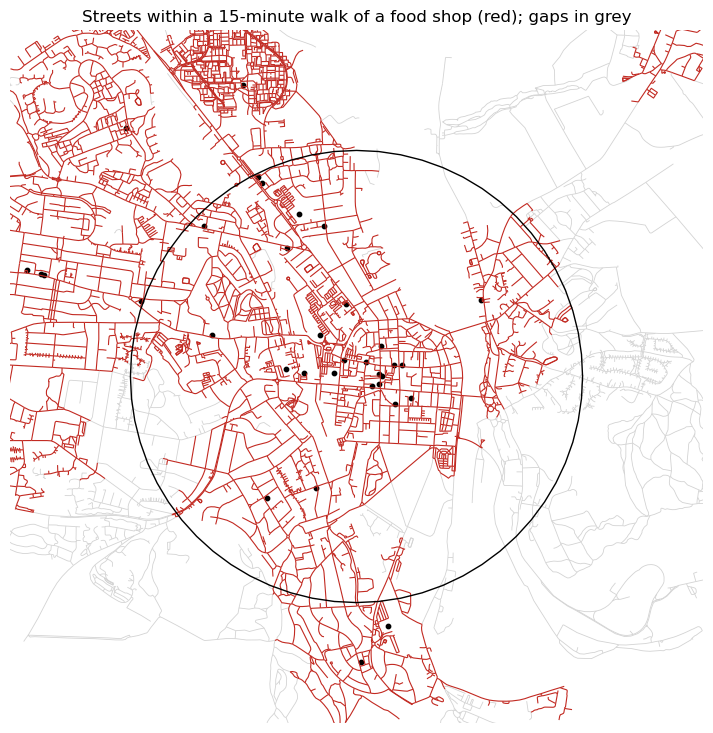

In [30]:
food_perth = services_perth[services_perth["service"] == "Food shop"]
food_nodes_perth = set(ox.distance.nearest_nodes(G_walkperth, food_perth.geometry.x, food_perth.geometry.y))
dist_to_food_perth = nx.multi_source_dijkstra_path_length(G_walkperth, food_nodes_perth, cutoff=PERTH_WALK_LIMIT, weight="length")

walk_edges = walk_edges.reset_index()
walk_edges["covered"] = walk_edges["u"].isin(set(dist_to_food_perth)) & walk_edges["v"].isin(set(dist_to_food_perth))

fig, ax = plt.subplots(figsize=(9, 9))
walk_edges[~walk_edges["covered"]].plot(ax=ax, color="lightgrey", linewidth=0.6)
walk_edges[walk_edges["covered"]].plot(ax=ax, color="#C22A22", linewidth=0.8)
food_perth.plot(ax=ax, color="black", markersize=10)
gpd.GeoSeries([neighbourhood], crs="EPSG:27700").boundary.plot(ax=ax, color="black", linewidth=1)
west, south, east, north = neighbourhood.buffer(PERTH_WALK_LIMIT).bounds      # zoom to the neighbourhood
ax.set_xlim(west, east)
ax.set_ylim(south, north)
ax.set_title("Streets within a 15-minute walk of a food shop (red); gaps in grey")
ax.set_axis_off()
plt.show()

## Challenge 6

Try any small city in the world. Replace the loading lines in 6.1 with these downloads, then run Part 6 again. Downloads can take a few minutes and may fail if the OpenStreetMap servers are busy; if so, try again later.

```python
CITY = "Girona, Spain"  # or "Leuven, Belgium", "Popayán, Colombia", your home town...
G_city = ox.graph_from_place(CITY, network_type="walk")
G_city = ox.project_graph(G_city).to_undirected()
crs = G_city.graph["crs"]
parks = ox.features_from_place(CITY, tags={"leisure": "park"}).to_crs(crs)
parks = parks[parks.geom_type.isin(["Polygon", "MultiPolygon"])].copy()
parks["area_m2"] = parks.area
buildings = ox.features_from_place(CITY, tags={"building": True}).to_crs(crs)
```
Important: Big cities like Girona or Leuven have proper boundaries and often will work, using graph_from_place, but If your town fails instantly, you can use: ox.graph_from_point((lat, lon), dist=2000, network_type="walk") and ox.features_from_point(...) instead of the _place version, small towns like St Andrews that has no official boundary in OpenStreetMap (lookup service called Nominatim.).

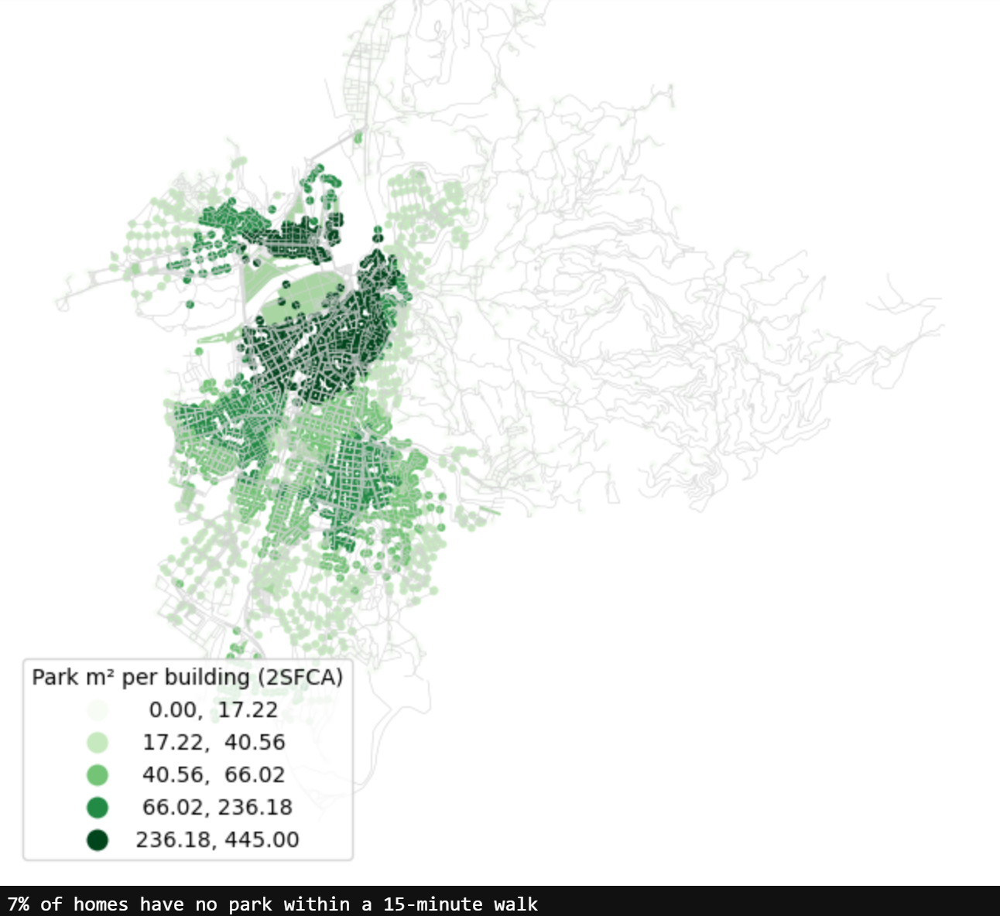

In [31]:
CITY = "Girona, Spain"  # or "Leuven, Belgium", "Popayán, Colombia", your home town...
CATCHMENT = 1200                        # metres: a 15-minute walk
G_city = ox.graph_from_place(CITY, network_type="walk")
G_city = ox.project_graph(G_city).to_undirected()
crs = G_city.graph["crs"]
gir_parks = ox.features_from_place(CITY, tags={"leisure": "park"}).to_crs(crs)
gir_parks = gir_parks[gir_parks.geom_type.isin(["Polygon", "MultiPolygon"])].copy()
gir_parks["area_m2"] = gir_parks.area
gir_buildings = ox.features_from_place(CITY, tags={"building": True}).to_crs(crs)
print(len(gir_parks), "parks and", len(gir_buildings), "buildings in", CITY)

C:\Users\silog\miniforge3\envs\ua\lib\site-packages\pandas\core\frame.py:721: DeprecationWarning: Passing a BlockManager to GeoDataFrame is deprecated and will raise in a future version. Use public APIs instead.
  warnings.warn(
C:\Users\silog\miniforge3\envs\ua\lib\site-packages\pandas\core\frame.py:721: DeprecationWarning: Passing a BlockManager to GeoDataFrame is deprecated and will raise in a future version. Use public APIs instead.
  warnings.warn(
C:\Users\silog\miniforge3\envs\ua\lib\site-packages\pandas\core\frame.py:721: DeprecationWarning: Passing a BlockManager to GeoDataFrame is deprecated and will raise in a future version. Use public APIs instead.
  warnings.warn(
C:\Users\silog\miniforge3\envs\ua\lib\site-packages\pandas\core\frame.py:721: DeprecationWarning: Passing a BlockManager to GeoDataFrame is deprecated and will raise in a future version. Use public APIs instead.
  warnings.warn(
C:\Users\silog\miniforge3\envs\ua\lib\site-packages\pandas\core\frame.py:721: Deprec

131 parks and 13042 buildings in Girona, Spain


C:\Users\silog\miniforge3\envs\ua\lib\site-packages\pandas\core\frame.py:721: DeprecationWarning: Passing a BlockManager to GeoDataFrame is deprecated and will raise in a future version. Use public APIs instead.
  warnings.warn(


In [32]:
gir_parks["intersections"] = ox.distance.nearest_nodes(G_city, gir_parks.representative_point().x, gir_parks.representative_point().y)
gir_buildings["intersections"] = ox.distance.nearest_nodes(G_city, gir_buildings.representative_point().x, gir_buildings.representative_point().y)

demand = gir_buildings["intersections"].value_counts()        # junction -> number of buildings
demand.head()

C:\Users\silog\miniforge3\envs\ua\lib\site-packages\pandas\core\frame.py:721: DeprecationWarning: Passing a BlockManager to GeoDataFrame is deprecated and will raise in a future version. Use public APIs instead.
  warnings.warn(
C:\Users\silog\miniforge3\envs\ua\lib\site-packages\pandas\core\frame.py:721: DeprecationWarning: Passing a BlockManager to GeoDataFrame is deprecated and will raise in a future version. Use public APIs instead.
  warnings.warn(


intersections
772261332    52
772232913    41
772009220    34
772234811    31
772214954    30
Name: count, dtype: int64

In [33]:
reach = {}          # which intersections can walk to each park
ratio = {}          # park area divided by the buildings that can reach it
print(type(gir_parks), len(gir_parks))
print(gir_parks.columns.tolist())

for park_id, park in gir_parks.iterrows():
    gir_nearby = nx.single_source_dijkstra_path_length(G_city, park['intersections'], cutoff=CATCHMENT, weight="length")
    gir_buildings_nearby = sum(demand.get(node, 0) for node in gir_nearby)
    reach[park_id] = gir_nearby
    ratio[park_id] = park["area_m2"] / gir_buildings_nearby if gir_buildings_nearby > 0 else 0

gir_parks["m2_per_building"] = pd.Series(ratio)
gir_parks.sort_values("m2_per_building", ascending=False)[["name", "area_m2", "m2_per_building"]].head(10).round(0)

<class 'geopandas.geodataframe.GeoDataFrame'> 131
['geometry', 'source', 'wheelchair', 'natural', 'addr:street', 'leisure', 'name', 'nodes', 'name:ca', 'wikidata', 'wikipedia', 'landuse', 'access', 'name:etymology:wikidata', 'local_code', 'motor_vehicle', 'maxspeed', 'alt_name', 'surface', 'addr:city', 'name:etymology:wikipedia', 'opening_hours', 'operator', 'ways', 'type', 'note', 'place', 'area_m2', 'intersections']


C:\Users\silog\miniforge3\envs\ua\lib\site-packages\pandas\core\frame.py:721: DeprecationWarning: Passing a BlockManager to GeoDataFrame is deprecated and will raise in a future version. Use public APIs instead.
  warnings.warn(
C:\Users\silog\miniforge3\envs\ua\lib\site-packages\pandas\core\frame.py:721: DeprecationWarning: Passing a BlockManager to GeoDataFrame is deprecated and will raise in a future version. Use public APIs instead.
  warnings.warn(


name   area_m2  \
element_type osmid                                                    
way          4793317                            la Devesa  289810.0   
             33131965           Parc de les Ribes del Ter   83627.0   
relation     974232                                   NaN  140204.0   
way          546099381                       Camp de Mart   57245.0   
relation     6007522                                  NaN   34376.0   
way          897736693   Parc de la Guingueta de Fontajau   27016.0   
relation     965051                                   NaN   35437.0   
             3984008                                  NaN    5167.0   
way          690578956                                NaN    4036.0   
             213470969  Parc de Jordi Vilamitjana i Pujol   21967.0   

                        m2_per_building  
element_type osmid                       
way          4793317              137.0  
             33131965             106.0  
relation     974232                66.0  
way          546099381             41.0  
relation     6007522               29.0  
way          897736693             27.0  
relation     965051                27.0  
             3984008               25.0  
way          690578956             23.0  
             213470969             19.0

In [34]:
city_nodes, city_edges = ox.graph_to_gdfs(G_city)
park_access = {node: 0.0 for node in G_city.nodes}

for park_id, gir_nearby in reach.items():
    for node in gir_nearby:
        park_access[node] += ratio[park_id]

city_nodes["park_access"] = pd.Series(park_access)

gir_homes_city = city_nodes[city_nodes.index.isin(demand.index)]       # junctions that have buildings
gir_homes_city["park_access"].describe().round(0)

C:\Users\silog\miniforge3\envs\ua\lib\site-packages\pandas\core\frame.py:721: DeprecationWarning: Passing a BlockManager to GeoDataFrame is deprecated and will raise in a future version. Use public APIs instead.
  warnings.warn(


count    3649.0
mean       99.0
std       114.0
min         0.0
25%        20.0
50%        51.0
75%        98.0
max       445.0
Name: park_access, dtype: float64

C:\Users\silog\miniforge3\envs\ua\lib\site-packages\pandas\core\frame.py:721: DeprecationWarning: Passing a BlockManager to GeoDataFrame is deprecated and will raise in a future version. Use public APIs instead.
  warnings.warn(
C:\Users\silog\miniforge3\envs\ua\lib\site-packages\pandas\core\frame.py:721: DeprecationWarning: Passing a BlockManager to GeoDataFrame is deprecated and will raise in a future version. Use public APIs instead.
  warnings.warn(
C:\Users\silog\miniforge3\envs\ua\lib\site-packages\pandas\core\frame.py:721: DeprecationWarning: Passing a BlockManager to GeoDataFrame is deprecated and will raise in a future version. Use public APIs instead.
  warnings.warn(
C:\Users\silog\miniforge3\envs\ua\lib\site-packages\pandas\core\frame.py:721: DeprecationWarning: Passing a BlockManager to GeoDataFrame is deprecated and will raise in a future version. Use public APIs instead.
  warnings.warn(


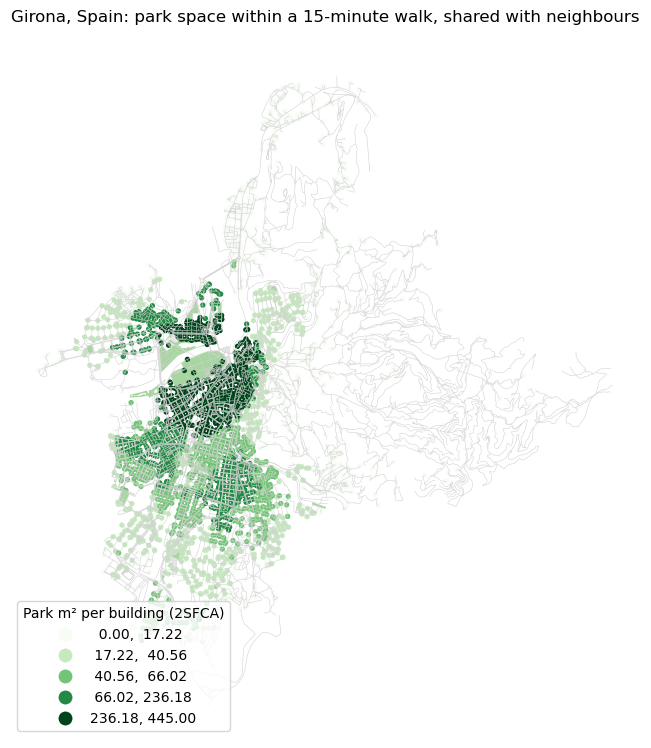

7% of homes have no park within a 15-minute walk


In [35]:
fig, ax = plt.subplots(figsize=(9, 9))
city_edges.plot(ax=ax, color="lightgrey", linewidth=0.4)
gir_parks.plot(ax=ax, color="#a8d5a2")
gir_homes_city.sort_values("park_access").plot(ax=ax, column="park_access", cmap="Greens", scheme="quantiles", k=5,
                                           markersize=8, legend=True,
                                           legend_kwds={"title": "Park m² per building (2SFCA)", "loc": "lower left"})
ax.set_title(f"{CITY}: park space within a 15-minute walk, shared with neighbours")
ax.set_axis_off()
plt.show()

print(f"{(gir_homes_city['park_access'] == 0).mean():.0%} of homes have no park within a 15-minute walk")

## Challenge 7: A 15-minute neighbourhood analysis

You now have all the tools to study accessibility on your own. Choose **one neighbourhood** from the list below (or another one you know well), and answer:

> **Is this a 15-minute neighbourhood? Who has good access to parks and everyday services, and where are the gaps?**

### Choose a neighbourhood

| City | Neighbourhood | `CENTRE` (latitude, longitude) |
|---|---|---|
| Paris | Le Marais | `(48.8590, 2.3620)` |

I chose Le Marais

---
*Data used in this lab includes: © OpenStreetMap contributors (ODbL); history via the ohsome API (HeiGIT); places © Overture Maps Foundation.*

### 5, 10, and 15 min isochrone

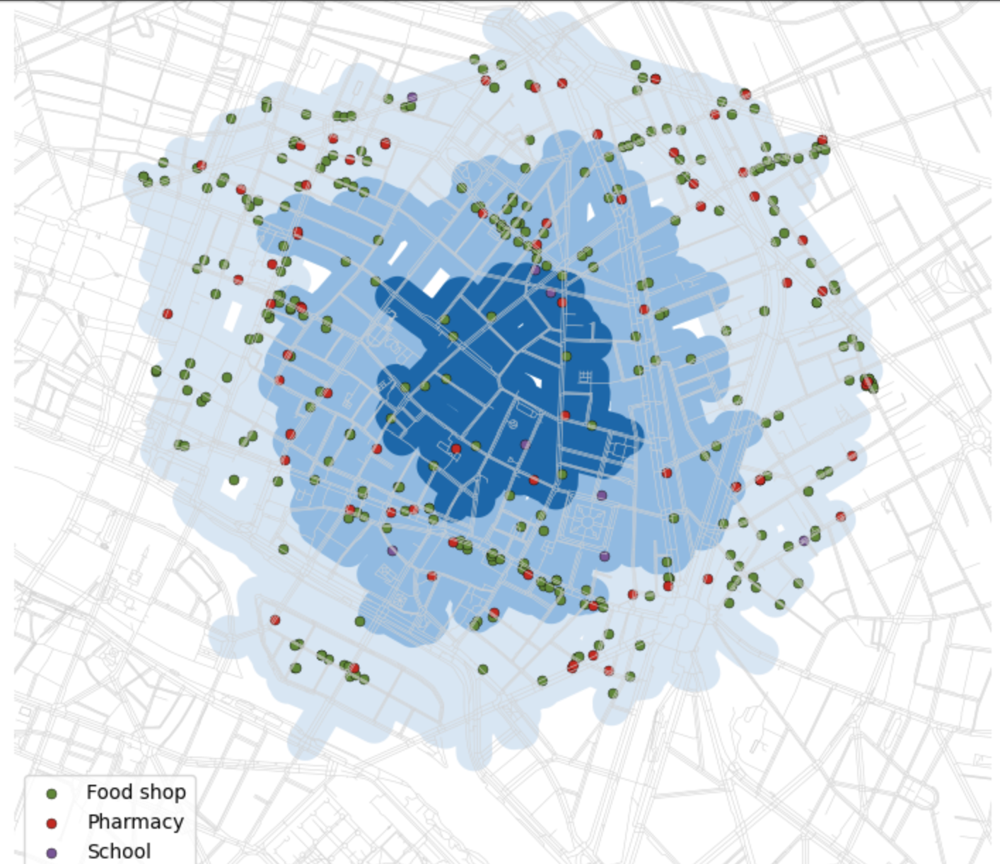

In [36]:
# loading data for Paris
import osmnx as ox
import networkx as nx
import numpy as np
import overturemaps
MAR_AREA = 2000          # metres: the neighbourhood area we study, also to reflect the 15-minute neighbourhood concept (15 minutes walking = 1200 metres, 20 minutes cycling = 5000 metres)
MAR_WALK_LIMIT = 1200    # 15 minutes walking
MAR_BIKE_LIMIT = 5000    # 20 minutes cycling
MAR_POINT = (48.8590, 2.3620)

mar_centre = gpd.GeoSeries.from_xy([MAR_POINT[1]], [MAR_POINT[0]], crs="EPSG:4326").to_crs(crs)
MAR_BOX = gpd.GeoSeries([mar_centre.buffer(MAR_AREA).iloc[0]], crs=crs).to_crs("EPSG:4326").total_bounds

G_marais = ox.graph_from_point(MAR_POINT, MAR_AREA, network_type="walk")
G_marais = ox.project_graph(G_marais).to_undirected()
crs = G_marais.graph['crs']
parks_marais = ox.features_from_point(MAR_POINT, {"leisure": "park"}, MAR_AREA).to_crs(crs)
parks_marais["area_m2"] = parks_marais.area
buildings_marais = ox.features_from_point(MAR_POINT, {"building": True}, MAR_AREA).to_crs(crs)
G_marais = ox.add_edge_speeds(G_marais)
G_marais = ox.add_edge_travel_times(G_marais)

marais_nodes, marais_edges = ox.graph_to_gdfs(G_marais)
print(len(parks_marais), "parks and", len(buildings_marais), "buildings in Le Marais")

C:\Users\silog\miniforge3\envs\ua\lib\site-packages\pyproj\transformer.py:820: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  return self._transformer._transform_point(
C:\Users\silog\miniforge3\envs\ua\lib\site-packages\pandas\core\frame.py:721: DeprecationWarning: Passing a BlockManager to GeoDataFrame is deprecated and will raise in a future version. Use public APIs instead.
  warnings.warn(
C:\Users\silog\miniforge3\envs\ua\lib\site-packages\pandas\core\frame.py:721: DeprecationWarning: Passing a BlockManager to GeoDataFrame is deprecated and will raise in a future version. Use public APIs instead.
  warnings.warn(
C:\Users\silog\miniforge3\envs\ua\lib\site-packages\pandas\core\frame.py:721: DeprecationWarning: Passing a BlockManager to GeoDataFrame is deprecated and will raise in a future version. Use public

168 parks and 23360 buildings in Le Marais


In [37]:
# getting all the places in the Le Marais 
marais_table = overturemaps.record_batch_reader("place", bbox=MAR_BOX, stac=True).read_all()
locations = marais_table.to_pandas()
locations["geometry"] = gpd.GeoSeries.from_wkb(locations["geometry"], crs="EPSG:4326").to_crs(crs)
locations = gpd.GeoDataFrame(locations, geometry="geometry")
locations["name"] = locations["names"].str.get("primary")      # each place can have several names; keep the main one

# checking the number of overture data points, the start of the basic_category info, and the crs
print(len(locations), "Overture places in Le Marais")
locations["basic_category"].value_counts().head(25)

73244 Overture places in Le Marais


basic_category
restaurant                            7676
fashion_and_apparel_store             5380
professional_service                  4437
corporate_or_business_office          2553
personal_or_beauty_service            2325
media_service                         2267
design_service                        2179
behavioral_or_mental_health_clinic    2150
financial_service                     1548
home_service                          1530
attorney_or_law_firm                  1463
bar                                   1411
real_estate_service                   1385
food_and_beverage_store               1373
casual_eatery                         1292
hotel                                 1193
social_or_community_service           1116
specialized_health_care               1058
wellness_service                      1047
art_gallery                           1034
hardware_home_and_garden_store        1008
travel_service                         912
event_or_party_service                 

In [38]:
# checking the column titles
locations.columns

Index(['id', 'geometry', 'confidence', 'websites', 'emails', 'socials',
       'phones', 'brand', 'addresses', 'names', 'sources', 'operating_status',
       'basic_category', 'taxonomy', 'version', 'bbox', 'name'],
      dtype='object')

In [39]:
# services: food and beverage stores, pharmacies, and high schools
marais_services = locations["basic_category"].str.contains("food_and_beverage|pharmacy|high_school", na=False)
overture_services = locations[marais_services & (locations["confidence"] >= 0.5)].copy()

print("Services in Overture:     ", len(overture_services))
print(overture_services["basic_category"].value_counts())
print()

Services in Overture:      1635
basic_category
food_and_beverage_store    1287
pharmacy_and_drug_store     314
high_school                  34
Name: count, dtype: int64



C:\Users\silog\miniforge3\envs\ua\lib\site-packages\pandas\core\frame.py:721: DeprecationWarning: Passing a BlockManager to GeoDataFrame is deprecated and will raise in a future version. Use public APIs instead.
  warnings.warn(
C:\Users\silog\miniforge3\envs\ua\lib\site-packages\pandas\core\frame.py:721: DeprecationWarning: Passing a BlockManager to GeoDataFrame is deprecated and will raise in a future version. Use public APIs instead.
  warnings.warn(


In [40]:
# creating a dictionary for services like the one for Perth in the lab notebook so that they show up when plotted on the isochrone map
MAR_SERVICES = {
    "food_and_beverage_store": "Food shop",
    "pharmacy_and_drug_store": "Pharmacy",
    "high_school": "School",
}
for mar_name in MAR_SERVICES:
    mar_points = overture_services[overture_services["basic_category"] == mar_name].geometry
    mar_walk_targets = ox.distance.nearest_nodes(G_marais, mar_points.x, mar_points.y)
    mar_walk_dist = nx.multi_source_dijkstra_path_length(G_marais, set(mar_walk_targets), weight="length")

    marais_home = ox.distance.nearest_nodes(G_marais, mar_centre.x.iloc[0], mar_centre.y.iloc[0])
    print(f"{mar_name:<17} {len(mar_points):>5} found") # 1287 of food_and_beverage_store, 314 of pharmacy_and_drug_store, 34 of high_school

# creating a new column in overture_services like the perth_services.gpkg data file from the lab workbook
overture_services["service_marais"] = overture_services["basic_category"].map(MAR_SERVICES)

C:\Users\silog\miniforge3\envs\ua\lib\site-packages\pandas\core\frame.py:721: DeprecationWarning: Passing a BlockManager to GeoDataFrame is deprecated and will raise in a future version. Use public APIs instead.
  warnings.warn(
C:\Users\silog\miniforge3\envs\ua\lib\site-packages\pandas\core\frame.py:721: DeprecationWarning: Passing a BlockManager to GeoDataFrame is deprecated and will raise in a future version. Use public APIs instead.
  warnings.warn(
C:\Users\silog\miniforge3\envs\ua\lib\site-packages\pandas\core\frame.py:721: DeprecationWarning: Passing a BlockManager to GeoDataFrame is deprecated and will raise in a future version. Use public APIs instead.
  warnings.warn(
C:\Users\silog\miniforge3\envs\ua\lib\site-packages\pandas\core\frame.py:721: DeprecationWarning: Passing a BlockManager to GeoDataFrame is deprecated and will raise in a future version. Use public APIs instead.
  warnings.warn(


food_and_beverage_store  1287 found


C:\Users\silog\miniforge3\envs\ua\lib\site-packages\pandas\core\frame.py:721: DeprecationWarning: Passing a BlockManager to GeoDataFrame is deprecated and will raise in a future version. Use public APIs instead.
  warnings.warn(
C:\Users\silog\miniforge3\envs\ua\lib\site-packages\pandas\core\frame.py:721: DeprecationWarning: Passing a BlockManager to GeoDataFrame is deprecated and will raise in a future version. Use public APIs instead.
  warnings.warn(
C:\Users\silog\miniforge3\envs\ua\lib\site-packages\pandas\core\frame.py:721: DeprecationWarning: Passing a BlockManager to GeoDataFrame is deprecated and will raise in a future version. Use public APIs instead.
  warnings.warn(


pharmacy_and_drug_store   314 found


C:\Users\silog\miniforge3\envs\ua\lib\site-packages\pandas\core\frame.py:721: DeprecationWarning: Passing a BlockManager to GeoDataFrame is deprecated and will raise in a future version. Use public APIs instead.
  warnings.warn(


high_school          34 found


C:\Users\silog\miniforge3\envs\ua\lib\site-packages\pandas\core\frame.py:721: DeprecationWarning: Passing a BlockManager to GeoDataFrame is deprecated and will raise in a future version. Use public APIs instead.
  warnings.warn(


In [41]:
MAR_WALK_SPEED = 80                    # metres per minute (4.8 km/h)
overture_services["node"] = ox.distance.nearest_nodes(G_marais, overture_services.geometry.x, overture_services.geometry.y)
nearest_overture_marais = nx.multi_source_dijkstra_path_length(G_marais, set(overture_services["node"]), weight="length")
marais_nodes["nearest_min_marais"] = pd.Series(nearest_overture_marais) / MAR_WALK_SPEED
crs = G_marais.graph["crs"]
marais_nodes.head

C:\Users\silog\miniforge3\envs\ua\lib\site-packages\pandas\core\frame.py:721: DeprecationWarning: Passing a BlockManager to GeoDataFrame is deprecated and will raise in a future version. Use public APIs instead.
  warnings.warn(
C:\Users\silog\miniforge3\envs\ua\lib\site-packages\pandas\core\frame.py:721: DeprecationWarning: Passing a BlockManager to GeoDataFrame is deprecated and will raise in a future version. Use public APIs instead.
  warnings.warn(


<bound method NDFrame.head of                         y              x          highway  street_count  \
osmid                                                                     
361029       5.410503e+06  453595.541917         crossing             1   
1464885511   5.410505e+06  453597.621284         crossing             4   
361032       5.411073e+06  453583.793606  traffic_signals             3   
11069078886  5.411076e+06  453574.859092         crossing             4   
11069078889  5.411068e+06  453582.136053         crossing             4   
...                   ...            ...              ...           ...   
14119501175  5.410230e+06  454546.795291              NaN             1   
14183378218  5.413005e+06  452464.161767              NaN             3   
14183378223  5.413080e+06  452486.216611              NaN             3   
14349326031  5.410285e+06  453828.653096              NaN             1   
14349326036  5.410491e+06  454201.019887              NaN             

In [42]:
def isochrone(G_marais, start_node, metres):
    reachable = nx.ego_graph(G_marais, start_node, radius=metres, distance="length")
    streets = ox.graph_to_gdfs(reachable, nodes=False)
    return unary_union(list(streets.buffer(50)))

C:\Users\silog\miniforge3\envs\ua\lib\site-packages\pandas\core\frame.py:721: DeprecationWarning: Passing a BlockManager to GeoDataFrame is deprecated and will raise in a future version. Use public APIs instead.
  warnings.warn(
C:\Users\silog\miniforge3\envs\ua\lib\site-packages\pandas\core\frame.py:721: DeprecationWarning: Passing a BlockManager to GeoDataFrame is deprecated and will raise in a future version. Use public APIs instead.
  warnings.warn(
C:\Users\silog\miniforge3\envs\ua\lib\site-packages\pandas\core\frame.py:721: DeprecationWarning: Passing a BlockManager to GeoDataFrame is deprecated and will raise in a future version. Use public APIs instead.
  warnings.warn(
C:\Users\silog\miniforge3\envs\ua\lib\site-packages\pandas\core\frame.py:721: DeprecationWarning: Passing a BlockManager to GeoDataFrame is deprecated and will raise in a future version. Use public APIs instead.
  warnings.warn(
C:\Users\silog\miniforge3\envs\ua\lib\site-packages\pandas\core\frame.py:721: Deprec

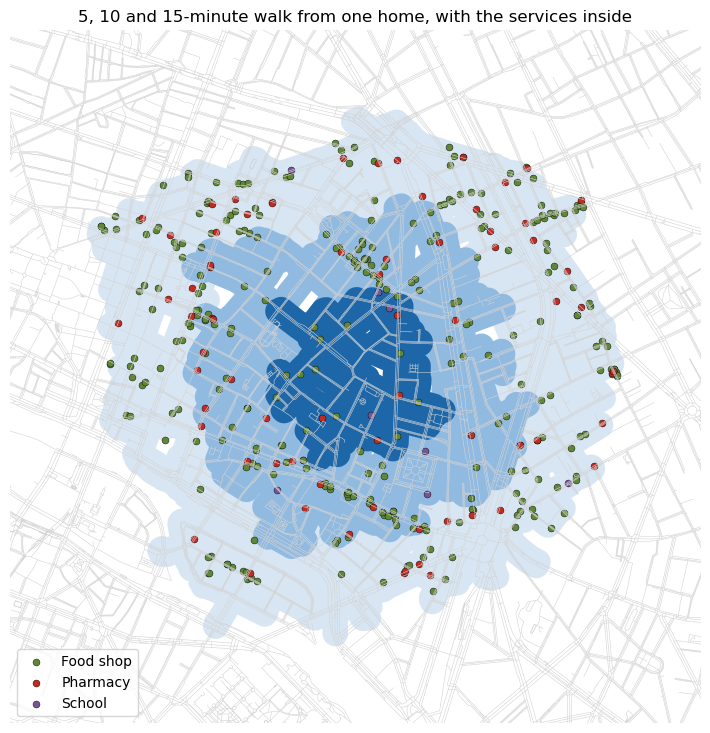

basic_category
food_and_beverage_store    294
pharmacy_and_drug_store     73
high_school                  8
Name: count, dtype: int64


In [43]:
marais_home = ox.distance.nearest_nodes(G_marais, mar_centre.x.iloc[0], mar_centre.y.iloc[0])   # the junction nearest the centre
crs = G_marais.graph["crs"]

fig, ax = plt.subplots(figsize=(9, 9))
marais_edges.plot(ax=ax, color="lightgrey", linewidth=0.4)
for minutes, colour in [(15, "#cfe0f0"), (10, "#7fb0dd"), (5, "#00539B")]:
    shape = isochrone(G_marais, marais_home, minutes * MAR_WALK_SPEED)
    gpd.GeoSeries([shape], crs="EPSG:3857").plot(ax=ax, color=colour, alpha=0.8)

iso15_marais = isochrone(G_marais, marais_home, 15 * MAR_WALK_SPEED)
inside_marais = overture_services[overture_services.within(iso15_marais)]
for mar_name, colour in zip(MAR_SERVICES, ["#608738", "#C22A22", "#785596", "#2a9d8f", "#F4C900"]):
    inside_marais[inside_marais["basic_category"] == mar_name].plot(ax=ax, color=colour, markersize=25, label=MAR_SERVICES[mar_name], edgecolor="black", linewidth=0.3)

ax.legend(loc="lower left")
ax.set_xlim(iso15_marais.bounds[0] - 300, iso15_marais.bounds[2] + 300)
ax.set_ylim(iso15_marais.bounds[1] - 300, iso15_marais.bounds[3] + 300)
ax.set_title("5, 10 and 15-minute walk from one home, with the services inside")
ax.set_axis_off()
plt.show()

print(inside_marais["basic_category"].value_counts())

### 2SFCA

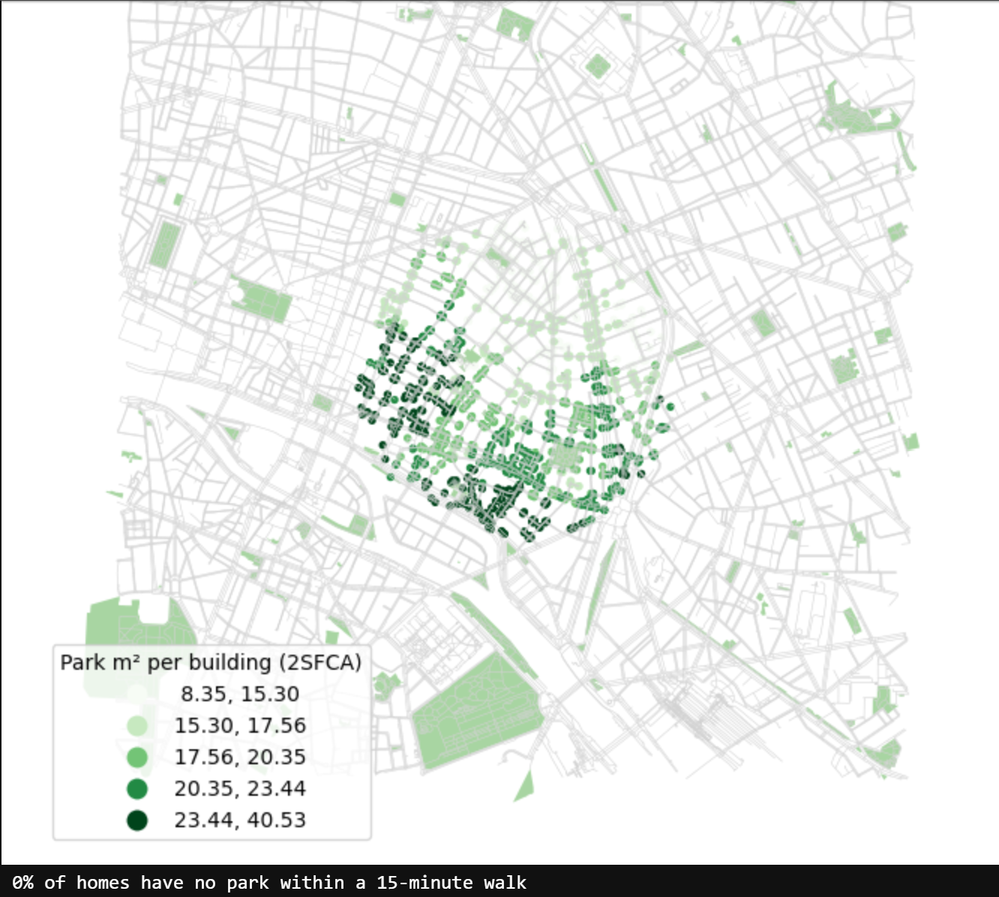

In [44]:
MAR_CITY = "Le Marais, Paris"
MAR_HOMES = 800 # only considering homes in an 800 m radius from MARAIS_POINT
parks_marais = parks_marais[parks_marais.geom_type.isin(["Polygon", "MultiPolygon"])].copy()

C:\Users\silog\miniforge3\envs\ua\lib\site-packages\pandas\core\frame.py:721: DeprecationWarning: Passing a BlockManager to GeoDataFrame is deprecated and will raise in a future version. Use public APIs instead.
  warnings.warn(
C:\Users\silog\miniforge3\envs\ua\lib\site-packages\pandas\core\frame.py:721: DeprecationWarning: Passing a BlockManager to GeoDataFrame is deprecated and will raise in a future version. Use public APIs instead.
  warnings.warn(


In [45]:
# creating nodes for parks and buildings
parks_marais["node"] = ox.distance.nearest_nodes(G_marais, parks_marais.representative_point().x, parks_marais.representative_point().y)
buildings_marais["node"] = ox.distance.nearest_nodes(G_marais, buildings_marais.representative_point().x, buildings_marais.representative_point().y)

# demand is how many buildings are attached to each junction
demand_marais = buildings_marais["node"].value_counts()
demand_marais.head() # 1316 nodes

C:\Users\silog\miniforge3\envs\ua\lib\site-packages\pandas\core\frame.py:721: DeprecationWarning: Passing a BlockManager to GeoDataFrame is deprecated and will raise in a future version. Use public APIs instead.
  warnings.warn(
C:\Users\silog\miniforge3\envs\ua\lib\site-packages\pandas\core\frame.py:721: DeprecationWarning: Passing a BlockManager to GeoDataFrame is deprecated and will raise in a future version. Use public APIs instead.
  warnings.warn(


node
11390701117    33
24558246       32
12178151018    25
26400894       23
11059749486    22
Name: count, dtype: int64

In [46]:
# using the 800 m radius to create a buffer around the center point                                  
neighbourhood = mar_centre.buffer(MAR_HOMES).iloc[0] # creating a neighborhood buffer of 800 m
marais_homes_city = marais_nodes[marais_nodes.index.isin(demand_marais.index)]      # every junction that has buildings
marais_neighbourhood = marais_homes_city[marais_homes_city.within(neighbourhood)].copy()    # selecting only homes in the 800 m radius

# 1316 residential junctions within the neighbourhood
print(len(marais_neighbourhood), "residential junctions within the neighbourhood")

1316 residential junctions within the neighbourhood


C:\Users\silog\miniforge3\envs\ua\lib\site-packages\pandas\core\frame.py:721: DeprecationWarning: Passing a BlockManager to GeoDataFrame is deprecated and will raise in a future version. Use public APIs instead.
  warnings.warn(
C:\Users\silog\miniforge3\envs\ua\lib\site-packages\pandas\core\frame.py:721: DeprecationWarning: Passing a BlockManager to GeoDataFrame is deprecated and will raise in a future version. Use public APIs instead.
  warnings.warn(
C:\Users\silog\miniforge3\envs\ua\lib\site-packages\pandas\core\frame.py:721: DeprecationWarning: Passing a BlockManager to GeoDataFrame is deprecated and will raise in a future version. Use public APIs instead.
  warnings.warn(


In [47]:
# determining the park space per building for each park

mar_reach = {}          # which junctions can walk to each park
mar_ratio = {}          # park area divided by the buildings that can reach it

for mar_park_id, mar_park in parks_marais.iterrows():
    nearby_mar = nx.single_source_dijkstra_path_length(G_marais, mar_park["node"], cutoff=MAR_WALK_LIMIT, weight="length") # the cutoff is the 15 min walk radius
    buildings_nearby_mar = sum(demand_marais.get(node, 0) for node in nearby_mar)
    mar_reach[mar_park_id] = nearby_mar
    mar_ratio[mar_park_id] = mar_park["area_m2"] / buildings_nearby_mar if buildings_nearby_mar > 0 else 0

parks_marais["m2_per_building"] = pd.Series(mar_ratio)
parks_marais.sort_values("m2_per_building", ascending=False)[["name", "area_m2", "m2_per_building"]].head(10).round(0)

C:\Users\silog\miniforge3\envs\ua\lib\site-packages\pandas\core\frame.py:721: DeprecationWarning: Passing a BlockManager to GeoDataFrame is deprecated and will raise in a future version. Use public APIs instead.
  warnings.warn(
C:\Users\silog\miniforge3\envs\ua\lib\site-packages\pandas\core\frame.py:721: DeprecationWarning: Passing a BlockManager to GeoDataFrame is deprecated and will raise in a future version. Use public APIs instead.
  warnings.warn(


name  \
element_type osmid                                                           
way          4221369                                    Jardin des Plantes   
             173204460                            Parc des Buttes-Chaumont   
             128206209                                Jardin du Luxembourg   
             358417047                     Jardin de Reuilly - Paul-Pernin   
             23644147    Jardin Tino Rossi - Musée de la Sculpture en P...   
             154892778                                  Parc de Belleville   
             22732250    Jardin des Grands-Explorateurs Marco Polo et R...   
             159103475                               Jardin Nelson Mandela   
             16405088                   Jardin Villemin - Mahsa Jîna Amini   
             1426361738                                 Square Marie Curie   

                          area_m2  m2_per_building  
element_type osmid                                  
way          4221369     225847.0            138.0  
             173204460   251508.0            121.0  
             128206209   217677.0             80.0  
             358417047    14202.0             14.0  
             23644147     28555.0             12.0  
             154892778    30863.0             11.0  
             22732250     10645.0              9.0  
             159103475    38173.0              8.0  
             16405088     18869.0              8.0  
             1426361738    6976.0              7.0

In [48]:
# adding up the park space each home can reach
marais_nodes, marais_edges = ox.graph_to_gdfs(G_marais)
marais_park_access = {node: 0.0 for node in G_marais.nodes}

for mar_park_id, nearby_mar in mar_reach.items():
    for node in nearby_mar:
        marais_park_access[node] += mar_ratio[mar_park_id]

marais_nodes["park_access"] = pd.Series(marais_park_access)

marais_homes = marais_nodes[marais_nodes.index.isin(marais_neighbourhood.index)]       # junctions that have buildings
marais_homes["park_access"].describe().round(0)

C:\Users\silog\miniforge3\envs\ua\lib\site-packages\pandas\core\frame.py:721: DeprecationWarning: Passing a BlockManager to GeoDataFrame is deprecated and will raise in a future version. Use public APIs instead.
  warnings.warn(


count    1316.0
mean       20.0
std         6.0
min         8.0
25%        16.0
50%        19.0
75%        23.0
max        41.0
Name: park_access, dtype: float64

C:\Users\silog\miniforge3\envs\ua\lib\site-packages\pandas\core\frame.py:721: DeprecationWarning: Passing a BlockManager to GeoDataFrame is deprecated and will raise in a future version. Use public APIs instead.
  warnings.warn(
C:\Users\silog\miniforge3\envs\ua\lib\site-packages\pandas\core\frame.py:721: DeprecationWarning: Passing a BlockManager to GeoDataFrame is deprecated and will raise in a future version. Use public APIs instead.
  warnings.warn(
C:\Users\silog\miniforge3\envs\ua\lib\site-packages\pandas\core\frame.py:721: DeprecationWarning: Passing a BlockManager to GeoDataFrame is deprecated and will raise in a future version. Use public APIs instead.
  warnings.warn(
C:\Users\silog\miniforge3\envs\ua\lib\site-packages\pandas\core\frame.py:721: DeprecationWarning: Passing a BlockManager to GeoDataFrame is deprecated and will raise in a future version. Use public APIs instead.
  warnings.warn(


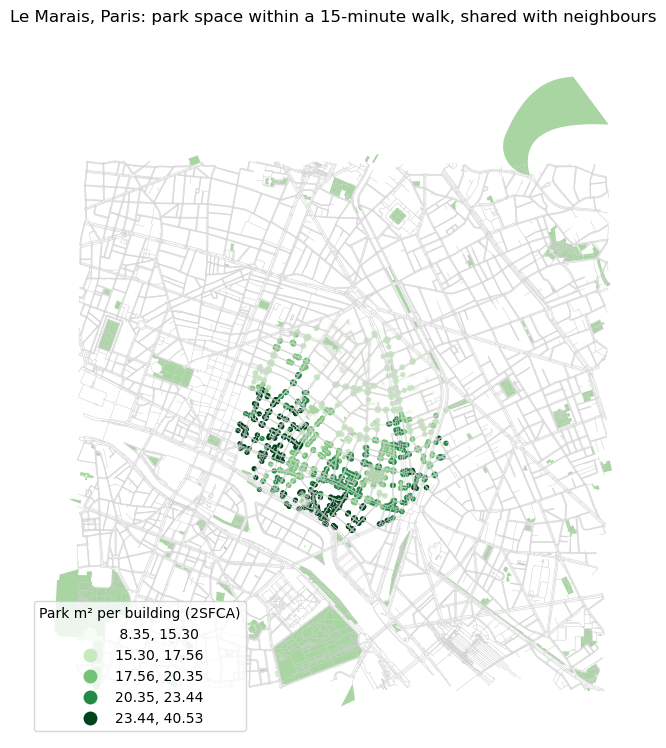

0% of homes have no park within a 15-minute walk


In [49]:
fig, ax = plt.subplots(figsize=(9, 9))
marais_edges.plot(ax=ax, color="lightgrey", linewidth=0.4)
parks_marais.plot(ax=ax, color="#a8d5a2")
marais_homes.sort_values("park_access").plot(ax=ax, column="park_access", cmap="Greens", scheme="quantiles", k=5,
                                           markersize=8, legend=True,
                                           legend_kwds={"title": "Park m² per building (2SFCA)", "loc": "lower left"})
ax.set_title(f"{MAR_CITY}: park space within a 15-minute walk, shared with neighbours")
ax.set_axis_off()
plt.show()

print(f"{(marais_homes['park_access'] == 0).mean():.0%} of homes have no park within a 15-minute walk")

### Summary Table

In [50]:
iso15_marais = isochrone(G_marais, marais_home, 15 * MAR_WALK_SPEED)
inside_marais = overture_services[overture_services.within(iso15_marais)]
service_counts = inside_marais["service_marais"].value_counts()

marais_summary = pd.Series({
    "Number of parks": len(parks_marais),
    "Number of buildings": len(buildings_marais),
    "Number of homes (junctions with buildings, within 800 m)": len(marais_homes),
    "Median park m2 per building": round(marais_homes["park_access"].median(), 1),
    "% of homes with no park within 15 mins": round((marais_homes["park_access"] == 0).mean() * 100, 1),
    **{f"{label} within 15 min of centre": int(service_counts.get(label, 0)) for label in MAR_SERVICES.values()},
})

marais_summary

C:\Users\silog\miniforge3\envs\ua\lib\site-packages\pandas\core\frame.py:721: DeprecationWarning: Passing a BlockManager to GeoDataFrame is deprecated and will raise in a future version. Use public APIs instead.
  warnings.warn(


Number of parks                                               167.0
Number of buildings                                         23360.0
Number of homes (junctions with buildings, within 800 m)     1316.0
Median park m2 per building                                    19.1
% of homes with no park within 15 mins                          0.0
Food shop within 15 min of centre                             294.0
Pharmacy within 15 min of centre                               73.0
School within 15 min of centre                                  8.0
dtype: float64

### Conclusions

**Is this a 15-minute neighbourhood? Who has good access to parks and everyday services, and where are the gaps?**

Le Marais has lots of accessible green space, evidenced by the fact that 0% of the 1316 buildings in the 800 m radius are further than a 15 minute walk from a park. In the 800 m neighbourhood, the buildings on the edge are closer to much larger parks and gardens outside of Le Marais than the ones within Le Marais itself. This would affect the park m2 per building value and the 2SFCA values, and likely overrepresent residents on the edge of the neighborhood compared to those in the center of the neighbourhood. The main limitation with this analysis is using buildings as a proxy for where people live. There are fewer parks toweards the north of Le Marais, 
Everyday services are common in the 5, 10, and 15 minute isochrones, with 3 schools, 4 pharmacies, and over 10 food and beverage shops in the 5 minute walk isochrone alone. There is a gap between the 10 and 15 minute boundaries in the north-north-western part of the isochrones with fewer food shops, pharmacies, and no schools, but those living there or using the buildings in that area can still walk to parks nearby.
Overall, Le Marais could be considered a 15-minute neighbourhood due to accessible important services like food, healthcare, and secondary education, and all residents are able to access ~19.1 m of park space within 15 minutes. Actual population data, organized in a similar way to the SIMD data would make the data even more informative about which residents actually have difficulty accessing the services and public areas of Le Marais.